# 06 · Regresión espacial y Machine Learning a escala

**Parte A. Explicar:** ¿qué factores geográficos se asocian a la perturbación? Se agregan los hexágonos de bosque a
resolución 8 (~0.74 km²) y se comparan MCO, el modelo de rezago espacial (SLM) y el de error espacial (SEM),
elegidos con los tests de multiplicadores de Lagrange.

**Parte B. Predecir:** clasificar a nivel de píxel (millones de filas) qué bosque se perdió.
- *Entrenar en pequeño, puntuar en grande*: muestra estratificada y puntuación distribuida con `mapInPandas`.
- **Validación cruzada por bloques espaciales**: la autocorrelación espacial infla las métricas aleatorias.
- **Calibración**: el modelo se entrena con clases balanceadas; sus probabilidades se corrigen a la prevalencia real
  y el umbral se elige maximizando F1 fuera de muestra.
- Evaluación final sobre todos los píxeles **no usados en el entrenamiento**.

In [0]:
%pip install -q rasterio pyproj h3 geopandas shapely esda libpysal spreg pykrige scikit-gstat mapclassify scikit-learn mlflow
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Raíz del repositorio (Git folder en Databricks o clon local)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from geocloud import config as C, dbx
spark = dbx.get_spark()
VOL = dbx.volume_path()
FIG = Path(VOL) / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Databricks:", dbx.is_databricks(), "| Volume:", VOL)

Databricks: True | Volume: /Volumes/workspace/madre_dios_rs/raw


In [0]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from geocloud import spatial

feat = spark.table(dbx.tbl("gold_h3_features")).toPandas().pipe(dbx.clean)
YEARS = sorted(int(c.split("_")[1]) for c in feat.columns if c.startswith("ndvi_") and c.split("_")[1].isdigit())
Y0, Y1 = YEARS[0], YEARS[-1]
gdf = spatial.h3_to_geodataframe(feat, crs_out=C.CRS_UTM)
# Hexágonos de bosque: al menos la mitad de su superficie era bosque en el año base (excluye ríos, poblados, no bosque)
BOSQUE = gdf["frac_bosque_y0"] >= 0.5 if "frac_bosque_y0" in gdf else pd.Series(True, index=gdf.index)
print(f"Hexágonos: {len(gdf):,} | de bosque en {Y0}: {BOSQUE.sum():,} | años: {YEARS}")

Hexágonos: 21,854 | de bosque en 2018: 16,601 | años: [2018, 2020, 2022, 2024, 2025]


In [0]:
# Capas de contexto cartográfico (leyenda, topónimos, escala y norte)
vec = Path(VOL) / "bronze" / "vector"
def capa(n):
    p = vec / f"{n}.geojson"
    return gpd.read_file(p).to_crs(C.CRS_UTM) if p.exists() else None

rios, vias, za, poblados = capa("rios"), capa("vias"), capa("zonas_amortiguamiento"), capa("poblados")
anp = capa("areas_protegidas_sernanp")
anp = anp if anp is not None else capa("areas_protegidas")
if vias is not None and "highway" in vias:
    vias = vias[vias["highway"].isin(["trunk", "primary"])]
if poblados is not None and len(poblados) > 15:
    poblados = poblados[poblados["fclass"].isin(["city", "town"])] if "fclass" in poblados else poblados.head(12)
BOUNDS = C.GRID_BOUNDS_UTM
CONTEXTO = {"Ríos": (rios, dict(color="#1f78b4", lw=0.8)),
            "Vía principal (Interoceánica)": (vias, dict(color="black", lw=1.1)),
            "ANP (SERNANP)": (anp, dict(color="purple", lw=1.1)),
            "Zona de amortiguamiento": (za, dict(color="darkorange", lw=1.0, ls="--"))}

def contexto(ax, legend=True, **kw):
    spatial.decorate_map(ax, BOUNDS, CONTEXTO, poblados, legend=legend, **kw)

## Parte A. Regresión espacial

In [0]:
import h3, spreg
covs = [c for c in ["dist_via_km", "dist_cauce_km", "en_anp", "en_za", "treecover2000"] if c in feat]
df = gdf[BOSQUE].dropna(subset=["d_pert"] + covs).copy()
df["h3_8"] = df.h3.map(lambda c: h3.cell_to_parent(c, C.H3_RES_COARSE))
agg = df.groupby("h3_8").agg(d_pert=("d_pert", "mean"), n=("h3", "size"),
                             **{c: (c, "mean") for c in covs}).reset_index()
agg = agg[agg.n >= 4].reset_index(drop=True)

X = pd.DataFrame(index=agg.index)
if "dist_via_km" in agg: X["log_dist_via"] = np.log1p(agg.dist_via_km)
if "dist_cauce_km" in agg: X["log_dist_cauce"] = np.log1p(agg.dist_cauce_km)
if "en_anp" in agg: X["frac_anp"] = agg.en_anp
if "en_za" in agg: X["frac_zona_amort"] = agg.en_za
if "treecover2000" in agg: X["cobertura_2000"] = agg.treecover2000 / 100
X = X.loc[:, X.std() > 1e-6]          # descarta covariables constantes (colinealidad con el intercepto)
y = agg[["d_pert"]].values

w8 = spatial.h3_weights(agg.h3_8, k=1)
if w8.islands:
    keep = ~agg.h3_8.isin(w8.islands)
    agg, X, y = agg[keep].reset_index(drop=True), X[keep].reset_index(drop=True), y[keep.values]
    w8 = spatial.h3_weights(agg.h3_8, k=1)
print(f"Unidades de análisis (H3 res 8, bosque): {w8.n:,} | covariables: {list(X.columns)}")

Unidades de análisis (H3 res 8, bosque): 2,410 | covariables: ['log_dist_via', 'log_dist_cauce', 'frac_anp', 'frac_zona_amort', 'cobertura_2000']


In [0]:
ols = spreg.OLS(y, X.values, w=w8, spat_diag=True, moran=True, name_y="d_pert", name_x=list(X.columns))
diag = pd.DataFrame({
    "estadístico": ["I de Moran (residuos)", "LM rezago", "LM error", "LM rezago robusto", "LM error robusto"],
    "valor": [ols.moran_res[0], ols.lm_lag[0], ols.lm_error[0], ols.rlm_lag[0], ols.rlm_error[0]],
    "p": [ols.moran_res[2], ols.lm_lag[1], ols.lm_error[1], ols.rlm_lag[1], ols.rlm_error[1]]})
print(f"MCO R² = {ols.r2:.3f}"); diag.round(4)

MCO R² = 0.030


,estadístico,valor,p
0,I de Moran (residuos),0.6821,0.0000
1,LM rezago,2760.1789,0.0000
2,LM error,2757.8084,0.0000
3,LM rezago robusto,2.7110,0.0997
4,LM error robusto,0.3406,0.5595


In [0]:
lag = spreg.ML_Lag(y, X.values, w=w8, method="LU", name_y="d_pert", name_x=list(X.columns))
err = spreg.ML_Error(y, X.values, w=w8, method="LU", name_y="d_pert", name_x=list(X.columns))
names = ["constante"] + list(X.columns)
coef = pd.DataFrame({"MCO": ols.betas.ravel(), "SLM": lag.betas.ravel()[:len(names)],
                     "SEM": err.betas.ravel()[:len(names)]}, index=names)
pz = pd.DataFrame({"p MCO": [t[1] for t in ols.t_stat], "p SLM": [t[1] for t in lag.z_stat[:len(names)]],
                   "p SEM": [t[1] for t in err.z_stat[:len(names)]]}, index=names)
coef = coef.join(pz)
coef.loc["rho (rezago)"] = [np.nan, lag.rho, np.nan, np.nan, np.nan, np.nan]
coef.loc["lambda (error)"] = [np.nan, np.nan, err.lam, np.nan, np.nan, np.nan]
coef.loc["log-verosimilitud"] = [ols.logll, lag.logll, err.logll, np.nan, np.nan, np.nan]
coef.loc["AIC"] = [ols.aic, lag.aic, err.aic, np.nan, np.nan, np.nan]
coef.round(4)

ML_Lag
ML_Error


,MCO,SLM,SEM,p MCO,p SLM,p SEM
constante,-0.1616,0.0400,0.1222,0.2549,0.6458,0.2183
log_dist_via,-0.0119,-0.0018,0.0004,0.0028,0.4535,0.9647
log_dist_cauce,-0.0212,-0.0057,-0.0220,0.0001,0.0825,0.0172
frac_anp,-0.0222,-0.0075,-0.0429,0.0084,0.1505,0.0243
frac_zona_amort,0.0110,0.0022,0.0076,0.0544,0.5368,0.5755
cobertura_2000,0.2437,-0.0224,-0.0633,0.0927,0.8015,0.5327
rho (rezago),NaN,0.7768,NaN,NaN,NaN,NaN
lambda (error),NaN,NaN,0.7788,NaN,NaN,NaN
log-verosimilitud,1814.0701,2778.1904,2781.3109,NaN,NaN,NaN
AIC,-3616.1403,-5542.3809,-5550.6219,NaN,NaN,NaN


**Lectura:** si los LM robustos favorecen el rezago y el SLM tiene menor AIC, la perturbación **se contagia** entre
unidades vecinas (expansión de frentes). Coeficientes negativos en `log_dist_cauce` o `log_dist_via` indican que la
perturbación disminuye al alejarse de los cauces o de la vía.

## Parte B. Clasificación de pérdida de bosque a nivel de píxel

In [0]:
from pyspark.sql import functions as F
silver = spark.table(dbx.tbl("silver_s2_pixeles"))
hansen = spark.table(dbx.tbl("silver_hansen_pixeles"))
base = ["b02", "b03", "b04", "b08", "b11", "b12", "ndvi", "nbr", "ndwi", "mndwi", "bsi"]
s0 = silver.filter(F.col("year") == Y0).select("row", "col", *[F.col(c).alias(f"{c}_t0") for c in base])
s1 = silver.filter(F.col("year") == Y1).select("row", "col", *[F.col(c).alias(f"{c}_t1") for c in base])
# Etiqueta: pérdida antrópica oficial (Geobosques) sobre bosque existente en Y0; se excluye la pérdida natural
if spark.catalog.tableExists(dbx.tbl("silver_geobosques_pixeles")):
    gbp = spark.table(dbx.tbl("silver_geobosques_pixeles"))
    previos = list(range(1, Y0 - 2000 + 1))
    lab = (gbp.filter(F.col("cobertura_gb").isin(2, 3, 4) & ~F.col("perdida_gb").isin(previos)
                      & (F.col("perdida_gb") != C.GEOBOSQUES_NATURAL_2025))
           .select("row", "col", "lon", "lat",
                   F.col("perdida_gb").isin(C.geobosques_codes(Y0, Y1)).cast("int").alias("label")))
    FUENTE = "Geobosques"
else:
    lab = (hansen.filter("treecover2000 >= 30")
           .select("row", "col", "lon", "lat",
                   F.col("lossyear").between(Y0 - 2000 + 1, min(Y1, 2024) - 2000).cast("int").alias("label")))
    FUENTE = "Hansen"
data = s0.join(s1, ["row", "col"]).join(lab, ["row", "col"])
for c in base:
    data = data.withColumn(f"{c}_d", F.col(f"{c}_t1") - F.col(f"{c}_t0"))
FEATURES = [f"{c}_{s}" for c in base for s in ("t0", "t1", "d")]
counts = {r.label: r["count"] for r in data.groupBy("label").count().collect()}
PI = counts.get(1, 0) / sum(counts.values())
print(f"Etiqueta: {FUENTE} | píxeles de bosque con dato en ambos años: {sum(counts.values()):,} "
      f"| clases: {counts} | prevalencia real π = {PI:.4f}")

Etiqueta: Geobosques | píxeles de bosque con dato en ambos años: 4,726,224 | clases: {1: 672758, 0: 4053466} | prevalencia real π = 0.1423


In [0]:
import h3
N_CLASE = 60_000
fr = {k: min(1.0, N_CLASE / v) for k, v in counts.items()}
pdf = data.sampleBy("label", fractions=fr, seed=42).toPandas().pipe(dbx.clean)
pdf["bloque"] = [h3.latlng_to_cell(la, lo, 6) for la, lo in zip(pdf.lat, pdf.lon)]   # ~36 km² por bloque
print(f"Muestra: {len(pdf):,} píxeles en {pdf.bloque.nunique()} bloques espaciales")

Muestra: 120,148 píxeles en 84 bloques espaciales


In [0]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

Xs, ys = pdf[FEATURES].fillna(0).values, pdf.label.values
rf = RandomForestClassifier(n_estimators=120, max_depth=14, min_samples_leaf=20,
                            class_weight="balanced", n_jobs=-1, random_state=42)
auc_rand = cross_val_score(rf, Xs, ys, cv=KFold(5, shuffle=True, random_state=42), scoring="roc_auc")
gkf = GroupKFold(min(5, pdf.bloque.nunique()))
oof = cross_val_predict(rf, Xs, ys, cv=gkf, groups=pdf.bloque, method="predict_proba")[:, 1]

def calibrar(p, pi=PI, pi_s=0.5):
    """Corrección por prevalencia (Saerens et al., 2002): de la prevalencia de entrenamiento a la real."""
    a = p * pi / pi_s
    return a / (a + (1 - p) * (1 - pi) / (1 - pi_s))

oof_cal = calibrar(oof)
# Pesos para que la muestra balanceada represente la prevalencia real al elegir el umbral
w_s = np.where(ys == 1, PI / ys.mean(), (1 - PI) / (1 - ys.mean()))
prec, rec, thr = precision_recall_curve(ys, oof_cal, sample_weight=w_s)
f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
UMBRAL = float(thr[np.argmax(f1[:-1])])
print(f"AUC-ROC validación aleatoria:          {auc_rand.mean():.4f} ± {auc_rand.std():.4f}")
print(f"AUC-ROC validación por bloques (H3 6): {roc_auc_score(ys, oof):.4f}")
print(f"Optimismo por autocorrelación espacial: {auc_rand.mean() - roc_auc_score(ys, oof):+.4f}")
print(f"AUC-PR por bloques a prevalencia real: {average_precision_score(ys, oof_cal, sample_weight=w_s):.4f} "
      f"(azar = {PI:.4f})")
print(f"Umbral óptimo (F1) sobre probabilidad calibrada: {UMBRAL:.3f}")

AUC-ROC validación aleatoria:          0.9148 ± 0.0013
AUC-ROC validación por bloques (H3 6): 0.9120
Optimismo por autocorrelación espacial: +0.0028
AUC-PR por bloques a prevalencia real: 0.7505 (azar = 0.1423)
Umbral óptimo (F1) sobre probabilidad calibrada: 0.331


2026/11/09 15:19:39 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
2026/11/09 15:19:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/09 15:19:40 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
🔗 View Logged Model at: https://dbc-0aa6ef08-f0c8.cloud.databricks.com/ml/experiments/918599281556707/models/m-ec9d9beb34a343d39733352906f87c75?o=7474650629917838


Modelo registrado en MLflow


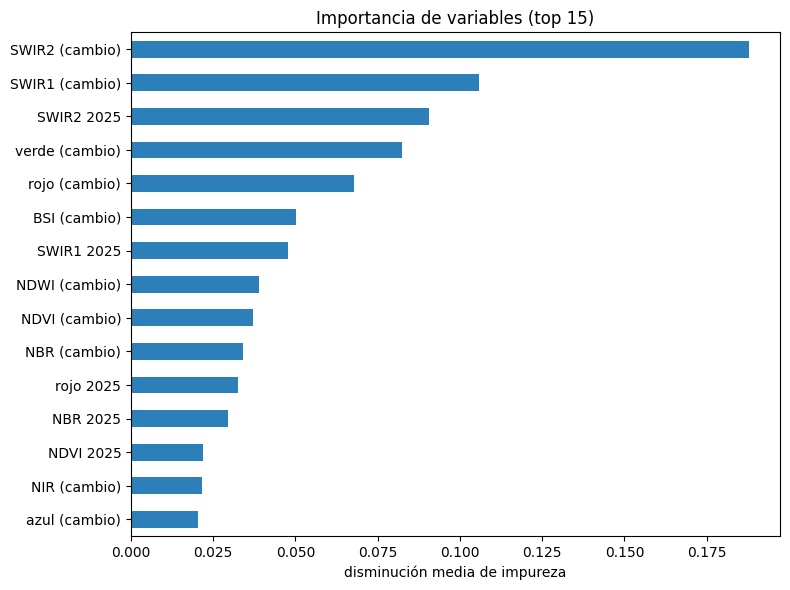

In [0]:
rf.fit(Xs, ys)
try:
    import mlflow, mlflow.sklearn
    with mlflow.start_run(run_name="rf_perdida_bosque_mdd"):
        mlflow.log_params({"n_estimators": 120, "max_depth": 14, "y0": Y0, "y1": Y1, "n_muestra": len(pdf),
                           "etiqueta": FUENTE, "umbral": UMBRAL, "prevalencia": PI})
        mlflow.log_metrics({"auc_aleatorio": auc_rand.mean(), "auc_bloques": roc_auc_score(ys, oof)})
        mlflow.sklearn.log_model(rf, "model", input_example=pdf[FEATURES].head(3))
    print("Modelo registrado en MLflow")
except Exception as e:
    print("MLflow no disponible en este entorno:", e)

nombres_b = {"b02": "azul", "b03": "verde", "b04": "rojo", "b08": "NIR", "b11": "SWIR1", "b12": "SWIR2"}
sufijo = {"t0": f" {Y0}", "t1": f" {Y1}", "d": " (cambio)"}
etq = [nombres_b.get(f.rsplit("_", 1)[0], f.rsplit("_", 1)[0].upper()) + sufijo[f.rsplit("_", 1)[1]] for f in FEATURES]
imp = pd.Series(rf.feature_importances_, index=etq).sort_values().tail(15)
imp.plot.barh(figsize=(8, 6), color="#2c7fb8", title="Importancia de variables (top 15)")
plt.xlabel("disminución media de impureza"); plt.tight_layout()
plt.savefig(FIG / "06_importancia.png", dpi=150); plt.show()

### Puntuación distribuida y evaluación fuera de la muestra de entrenamiento

In [0]:
from pyspark.sql import types as T
model, feats, umbral, pi = rf, FEATURES, UMBRAL, PI
out_schema = T.StructType([T.StructField("row", T.IntegerType()), T.StructField("col", T.IntegerType()),
                           T.StructField("lon", T.DoubleType()), T.StructField("lat", T.DoubleType()),
                           T.StructField("label", T.IntegerType()), T.StructField("prob", T.FloatType()),
                           T.StructField("pred", T.IntegerType())])

def score(it):
    for p in it:
        raw = model.predict_proba(p[feats].fillna(0).values)[:, 1]
        a = raw * pi / 0.5
        cal = a / (a + (1 - raw) * (1 - pi) / 0.5)
        yield pd.DataFrame({"row": p.row, "col": p.col, "lon": p.lon, "lat": p.lat, "label": p.label,
                            "prob": cal.astype("float32"), "pred": (cal >= umbral).astype("int32")})

pred = data.select("row", "col", "lon", "lat", "label", *FEATURES).mapInPandas(score, schema=out_schema)
dbx.save_table(pred, "gold_pred_perdida_pixel")
pred = spark.table(dbx.tbl("gold_pred_perdida_pixel"))
entrenados = spark.createDataFrame(pd.DataFrame(pdf[["row", "col"]]).astype("int32"))
evalu = pred.join(entrenados, ["row", "col"], "left_anti")
cm = evalu.groupBy("label", "pred").count().toPandas().pipe(dbx.clean).pivot(index="label", columns="pred", values="count").fillna(0)
tp, fp, fn, tn = cm.loc[1, 1], cm.loc[0, 1], cm.loc[1, 0], cm.loc[0, 0]
prec_, rec_ = tp / (tp + fp), tp / (tp + fn)
print("Matriz de confusión (píxeles no usados en el entrenamiento):")
print(cm.rename(index={0: "real: sin pérdida", 1: "real: pérdida"}, columns={0: "pred: sin pérdida", 1: "pred: pérdida"}).astype(int))
print(f"Precisión {prec_:.3f} | Sensibilidad {rec_:.3f} | F1 {2*prec_*rec_/(prec_+rec_):.3f} | "
      f"Exactitud {(tp+tn)/cm.values.sum():.3f}")
area_esperada = evalu.agg(F.sum("prob")).first()[0] * 0.04
print(f"Área de pérdida: oficial {(tp+fn)*0.04:,.0f} ha | esperada por el modelo (suma de probabilidades calibradas) "
      f"{area_esperada:,.0f} ha | clasificada con el umbral F1 {(tp+fp)*0.04:,.0f} ha")
print("El umbral F1 optimiza la detección píxel a píxel; para estimar superficie se usa la suma de probabilidades.")

Matriz de confusión (píxeles no usados en el entrenamiento):
pred               pred: sin pérdida  pred: pérdida
label                                              
real: sin pérdida            3839268         153913
real: pérdida                 184931         427964
Precisión 0.735 | Sensibilidad 0.698 | F1 0.716 | Exactitud 0.926
Área de pérdida: oficial 24,516 ha | esperada por el modelo (suma de probabilidades calibradas) 24,844 ha | clasificada con el umbral F1 23,275 ha
El umbral F1 optimiza la detección píxel a píxel; para estimar superficie se usa la suma de probabilidades.


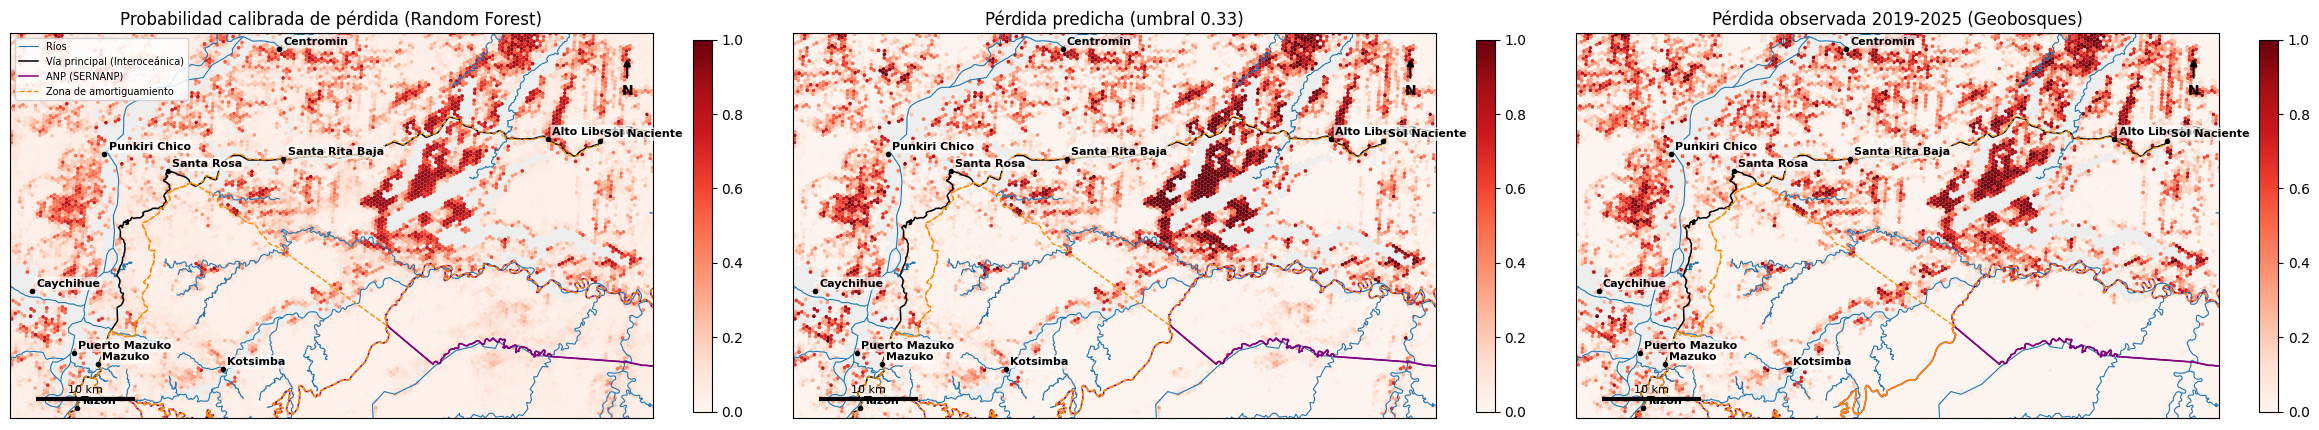

Correlación por hexágono (pérdida predicha vs Geobosques): 0.917


In [0]:
pred.createOrReplaceTempView("pred")
ph = spark.sql(f"""
SELECT h3_longlatash3string(lon, lat, {C.H3_RES_FINE}) AS h3,
       AVG(prob) AS prob_modelo, AVG(pred) AS frac_predicha, AVG(label) AS perdida_observada, COUNT(*) AS n
FROM pred GROUP BY 1 HAVING n >= 50""").toPandas().pipe(dbx.clean)
gph = spatial.h3_to_geodataframe(ph, crs_out=C.CRS_UTM)
fig, ax = plt.subplots(1, 3, figsize=(24, 6.5))
for a, col, t in [(ax[0], "prob_modelo", "Probabilidad calibrada de pérdida (Random Forest)"),
                  (ax[1], "frac_predicha", f"Pérdida predicha (umbral {UMBRAL:.2f})"),
                  (ax[2], "perdida_observada", f"Pérdida observada {Y0+1}-{Y1} ({FUENTE})")]:
    gdf.plot(ax=a, color="#ededed", linewidth=0)
    gph.plot(column=col, cmap="Reds", vmin=0, vmax=1, linewidth=0, ax=a, legend=True, legend_kwds={"shrink": 0.6})
    contexto(a, legend=(a is ax[0]))
    a.set_title(t)
plt.tight_layout(); plt.savefig(FIG / "06_prediccion.png", dpi=150); plt.show()
print(f"Correlación por hexágono (pérdida predicha vs {FUENTE}): {ph[['frac_predicha','perdida_observada']].corr().iloc[0,1]:.3f}")

## Conclusiones técnicas

1. **Escala:** el procesamiento se expresó como operaciones sobre DataFrames (teselas → píxeles → hexágonos), así
   que el mismo código sirve para un corredor o para toda la Amazonía peruana.
2. **Estadística espacial:** la perturbación muestra autocorrelación positiva fuerte, clusters Pérdida-Pérdida y
   puntos calientes Gi* en el cinturón minero, una vez excluida la dinámica natural de los ríos.
3. **Geoestadística:** el kriging reconstruye zonas ocultas por nubes con error e incertidumbre cuantificados.
4. **Patrones puntuales:** los nuevos frentes forman parches agrupados más allá de lo que explica el bosque disponible.
5. **ML:** la validación por bloques espaciales y la calibración a la prevalencia real son imprescindibles para
   reportar métricas y áreas honestas.